<h1>Trabajo Práctico Final Integrador</h1>
<h2>Información acerca del Dataset</h2>

<b>Nombre: </b> Logistic regression To predict heart disease

<b>Link: </b> https://www.kaggle.com/datasets/dileep070/heart-disease-prediction-using-logistic-regression?resource=download

<b>Descripción: </b> Este dataset se encuentra disponible en Kaggle, pertenece a un estudio cardiovascular en curso sobre los residentes de la cidad de Framingham, Massachusetts, Estados Unidos. El objetivo de la clasificacion es predecir si un paciente tiene riesgo de enfermedad coronaria en los proximos 10 años.

otros detalles: Framingham Risk Score
Sistema de puntos por sexo que suma:

Edad
Colesterol total
HDL
Presión arterial sistólica (con/sin tratamiento)
Tabaquismo
La suma de puntos se mapea a una tabla de riesgo porcentual. La fórmula subyacente es un modelo de Cox:

Riesgo=1−S 
0
exp(∑β 
i
​
 x 
i
​
 − 
βX
ˉ
​
 )
​
 

donde 
S 
0
​
  es la supervivencia basal a 10 años, 
β 
i
​
  son los coeficientes y 
x 
i
​
  los factores de riesgo (log-transformados). 

Pooled Cohort Equations (PCE) – ACC/AHA 2013
Modelo de Cox con riesgos proporcionales, específico por sexo y raza.  Variables:

Edad (y edad²)
Colesterol total
HDL
PAS (tratada/no tratada)
Diabetes
Tabaquismo
Términos de interacción edad × colesterol, edad × HDL, edad × PAS
Misma estructura: 
R 
10
​
 =1−S 
0
exp(LP−M)
​
 , donde 
LP es el predictor lineal y 
M su media poblacional. 

Categorías de riesgo (PCE)
Riesgo 10 años	Categoría
< 5%	Bajo
5 – 7.4%	Fronterizo
7.5 – 19.9%	Intermedio
≥ 20%	Alto

<h3>Exploracion del Dataset </h3>

In [12]:
import pandas as pd
import numpy as np

df = pd.read_csv("framingham.csv")

print(df.head())
print(df.shape)

   male  age  education  currentSmoker  cigsPerDay  BPMeds  prevalentStroke  \
0     1   39        4.0              0         0.0     0.0                0   
1     0   46        2.0              0         0.0     0.0                0   
2     1   48        1.0              1        20.0     0.0                0   
3     0   61        3.0              1        30.0     0.0                0   
4     0   46        3.0              1        23.0     0.0                0   

   prevalentHyp  diabetes  totChol  sysBP  diaBP    BMI  heartRate  glucose  \
0             0         0    195.0  106.0   70.0  26.97       80.0     77.0   
1             0         0    250.0  121.0   81.0  28.73       95.0     76.0   
2             0         0    245.0  127.5   80.0  25.34       75.0     70.0   
3             1         0    225.0  150.0   95.0  28.58       65.0    103.0   
4             0         0    285.0  130.0   84.0  23.10       85.0     85.0   

   TenYearCHD  
0           0  
1           0  
2 

In [14]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
memory usage: 529.9 KB


In [15]:
# Contar los valores faltantes por columna
df.isnull().sum()

male                 0
age                  0
education          105
currentSmoker        0
cigsPerDay          29
BPMeds              53
prevalentStroke      0
prevalentHyp         0
diabetes             0
totChol             50
sysBP                0
diaBP                0
BMI                 19
heartRate            1
glucose            388
TenYearCHD           0
dtype: int64

In [ ]:
# Observar la variable objetivo
df["TenYearCHD"].value_counts()

TenYearCHD
0    3594
1     644
Name: count, dtype: int64

In [17]:
# Porcentaje de registros por clase
df["TenYearCHD"].value_counts(normalize=True) * 100

TenYearCHD
0    84.804153
1    15.195847
Name: proportion, dtype: float64

In [12]:
print("Dimensiones:", df.shape)

print("\nInformación general:")
df.info()

print("\nValores nulos:")
print(df.isnull().sum())

print("\nDistribución de la variable objetivo:")
print(df["TenYearCHD"].value_counts())

Dimensiones: (4238, 16)

Información general:
<class 'pandas.DataFrame'>
RangeIndex: 4238 entries, 0 to 4237
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   male             4238 non-null   int64  
 1   age              4238 non-null   int64  
 2   education        4133 non-null   float64
 3   currentSmoker    4238 non-null   int64  
 4   cigsPerDay       4209 non-null   float64
 5   BPMeds           4185 non-null   float64
 6   prevalentStroke  4238 non-null   int64  
 7   prevalentHyp     4238 non-null   int64  
 8   diabetes         4238 non-null   int64  
 9   totChol          4188 non-null   float64
 10  sysBP            4238 non-null   float64
 11  diaBP            4238 non-null   float64
 12  BMI              4219 non-null   float64
 13  heartRate        4237 non-null   float64
 14  glucose          3850 non-null   float64
 15  TenYearCHD       4238 non-null   int64  
dtypes: float64(9), int64(7)
m

In [18]:
df.duplicated().sum()

np.int64(0)

In [ ]:
# Estadísticas descriptivas de las variables
df.describe().T

,count,mean,std,min,25%,50%,75%,max
male,4238.0,0.429212,0.495022,0.00,0.00,0.0,1.000,1.0
age,4238.0,49.584946,8.572160,32.00,42.00,49.0,56.000,70.0
education,4133.0,1.978950,1.019791,1.00,1.00,2.0,3.000,4.0
currentSmoker,4238.0,0.494101,0.500024,0.00,0.00,0.0,1.000,1.0
cigsPerDay,4209.0,9.003089,11.920094,0.00,0.00,0.0,20.000,70.0
BPMeds,4185.0,0.029630,0.169584,0.00,0.00,0.0,0.000,1.0
prevalentStroke,4238.0,0.005899,0.076587,0.00,0.00,0.0,0.000,1.0
prevalentHyp,4238.0,0.310524,0.462763,0.00,0.00,0.0,1.000,1.0
diabetes,4238.0,0.025720,0.158316,0.00,0.00,0.0,0.000,1.0
totChol,4188.0,236.721585,44.590334,107.00,206.00,234.0,263.000,696.0


Verifico si las clases están balanceadas, la clase 0 es si no desarrollo enfemerdad cardíaca, la clase 1 si la desarrolló

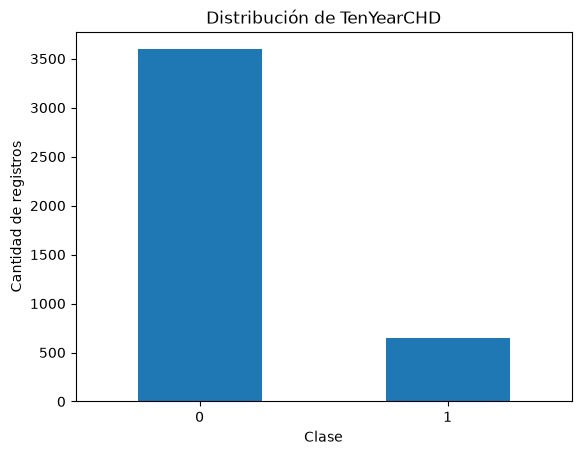

In [14]:
import matplotlib.pyplot as plt

df["TenYearCHD"].value_counts().sort_index().plot(
    kind="bar",
    rot=0
)

plt.title("Distribución de TenYearCHD")
plt.xlabel("Clase")
plt.ylabel("Cantidad de registros")
plt.show()

Por lo analizado ahora si se puede definir el problema.
<u>Problema:</u> predecir si una persona presenta riesgo de desarrollar enfermedad coronaria (CHD) durante los próximos diez años.
- 0: no desarrolló CHD durante ese período.
- 1: desarrolló CHD durante ese período.
La variable objetivo será TenYearCHD.

Pero según lo observado hay un desbalance de clases que debe ser considerado